# Browser Workflow Automation Agent

**Executed offline notebook**. All sources are fictional and requests run the same `agent.py` code as the CLI and Streamlit app. The negative case deliberately injects a tool failure.

In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image
BASE=Path.cwd()
sys.path.insert(0,str(BASE.parent))
from agent import run
CASES=json.loads((BASE/"data/eval_cases.json").read_text())
print("Dataset:",BASE.name,"| tasks:",len(CASES))

Dataset: 08-browser-workflow-agent | tasks: 4


## Successful / approval-safe execution (actual local workflow)

In [2]:
case=next(c for c in CASES if c["id"]=='prepared')
success=run(case["request"],BASE,case.get("fault"))
print(json.dumps({"status":success["status"],"answer":success["answer"],"evidence":success["evidence"],"trace":success["trace"]},indent=2,ensure_ascii=False))
assert success["status"] == case["expected_status"]

{
  "status": "needs_approval",
  "answer": "Form fill plan prepared; awaiting explicit submit approval. No submission performed.",
  "evidence": [
    {
      "selector": "[name='supplier_name']",
      "value": "Acme Parts"
    },
    {
      "selector": "[name='email']",
      "value": "sales@acme.example"
    },
    {
      "selector": "[name='country']",
      "value": "India"
    },
    {
      "selector": "[name='tax_id']",
      "value": "GST-DEMO-001"
    }
  ],
  "trace": [
    {
      "tool": "inspect_form",
      "ok": true,
      "elapsed_ms": 0.449,
      "output_preview": "['supplier_name', 'email', 'country', 'tax_id']"
    },
    {
      "tool": "suppliers",
      "ok": true,
      "elapsed_ms": 0.183,
      "output_preview": "[{'supplier_id': 'SUP-1', 'supplier_name': 'Acme Parts', 'email': 'sales@acme.example', 'country': 'India', 'tax_id': 'GST-DEMO-001'}, {'supplier_id': 'SUP-2', 'supplier_name': 'Ba"
    },
    {
      "tool": "validate",
      "ok": true,
      "

## Failure case with a real injected tool exception

In [3]:
case=next(c for c in CASES if c["id"]=='fault')
failure=run(case["request"],BASE,case["fault"])
print(json.dumps({"status":failure["status"],"answer":failure["answer"],"trace":failure["trace"]},indent=2,ensure_ascii=False))
assert failure["status"] == "error"
assert any(not x["ok"] for x in failure["trace"])

{
  "status": "error",
  "answer": "RuntimeError: Injected tool fault: inspect_form",
  "trace": [
    {
      "tool": "inspect_form",
      "ok": false,
      "elapsed_ms": 0.003,
      "error": "RuntimeError: Injected tool fault: inspect_form"
    }
  ]
}


## Archived fixture evaluation and generated evidence chart

Passed 4 of 4 fixture tasks
Tool failure rate 0.1111 | Mean latency (ms) 0.166 | Hosted model spend ($) 0.0


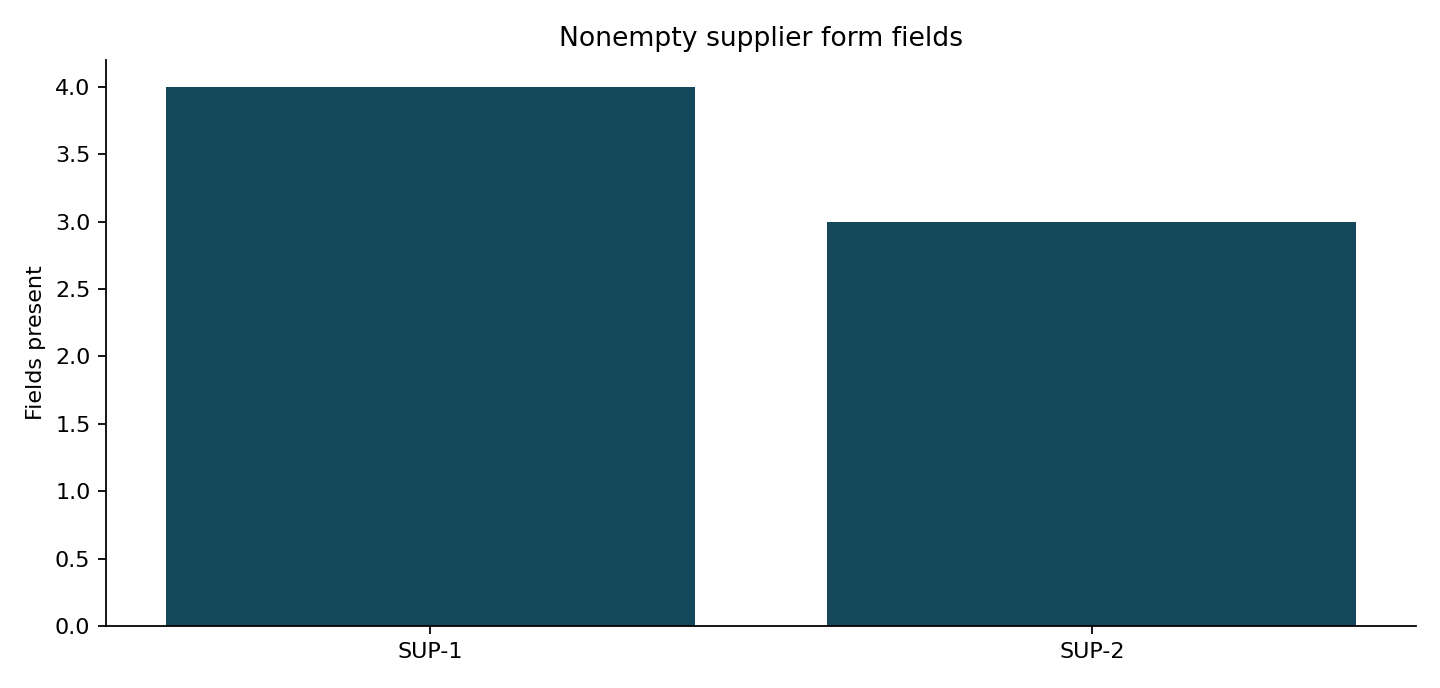

In [4]:
report=json.loads((BASE/"outputs/evaluation.json").read_text())
print("Passed",report["passed"],"of",report["cases"],"fixture tasks")
print("Tool failure rate",report["tool_failure_rate"],"| Mean latency (ms)",report["mean_latency_ms"],"| Hosted model spend ($)",report["total_model_api_cost_usd"])
display(Image(filename=str(BASE/"outputs/overview.png")))